# Solver harness

Runs all solvers from `solvers.py` on the same problem and compares them side by side.

In [114]:
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from solvers import pgd, pgd_maxent, pgd_maxent_jax, ipm_chol, sparse_prec_ipm, clarabel_solver, strip_compile_iter

## Problem

In [115]:
def make_problem(d=32, fraction_offdiag=0.2, tau_diag=0.2, seed=42):
    """Random covariance estimation problem."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((d, d)))
    eigvals = np.clip(np.exp(rng.standard_normal(d)), 0.1, 10.0)
    Sigma_true = Q @ np.diag(eigvals) @ Q.T

    n_off = int(fraction_offdiag * (d * (d - 1) // 2))
    diag_inds = [(i, i) for i in range(d)]
    pool = [(i, j) for i in range(d) for j in range(i + 1, d)]
    chosen = rng.choice(len(pool), min(n_off, len(pool)), replace=False)
    off_inds = [pool[k] for k in chosen]

    inds = np.array(diag_inds + off_inds)
    tau  = np.array([tau_diag] * d + [tau_diag * 2.0] * n_off)

    A = np.zeros((d, d))
    for k, (i, j) in enumerate(inds):
        noise  = rng.normal(0, tau[k])
        A[i, j] = Sigma_true[i, j] + noise
        A[j, i] = A[i, j]

    return Sigma_true, A, inds, tau


d        = 32
tau_diag = 0.2    # increase for high-noise (PSD-boundary) regime

Sigma_true, A, inds, tau = make_problem(d=d, tau_diag=tau_diag)
print(f'd = {d},  |S| = {len(inds)}  ({d} diag + {len(inds)-d} off-diag)')
print(f'True eigenvalue range: [{np.linalg.eigvalsh(Sigma_true).min():.3f}, {np.linalg.eigvalsh(Sigma_true).max():.3f}]')

d = 32,  |S| = 131  (32 diag + 99 off-diag)
True eigenvalue range: [0.113, 10.000]


## Run all solvers

In [ ]:
print('pgd ...')
S_pgd, h_pgd = pgd(A, inds, tau, max_iters=2000)

print('pgd_maxent ...')
S_pgm, h_pgm = pgd_maxent(A, inds, tau, pgd_iters=2000, lbfgs_iters=500)

print('pgd_maxent_jax ...')
S_pgj, h_pgj = pgd_maxent_jax(A, inds, tau, max_iters=2000)
h_pgj_plot, pgj_compile_time = strip_compile_iter(h_pgj)
print(f'  (compile time: {pgj_compile_time:.2f}s)')

print('ipm_chol ...')
S_ipm, h_ipm = ipm_chol(A, inds, tau, max_outer=40, max_inner=200, eps=1e-8)

print('sparse_prec_ipm ...')
S_sp,  h_sp  = sparse_prec_ipm(A, inds, tau, K_barrier=True, max_outer=50, max_inner=1000, mu_init=1e-2, eps=1e-40)
h_sp_plot, sp_compile_time = strip_compile_iter(h_sp)
print(f'  (compile time: {sp_compile_time:.2f}s)')

print('clarabel ...')
S_clar, h_clar = clarabel_solver(A, inds, tau)

print('done.')

pgd ...
pgd_maxent ...
pgd_maxent_jax ...
  [PGD INIT] S has negative eigenvalues: min=-9.576884e-01, needs PSD projection
  [PGD INIT] S diagonal before projection: [1.41969634 1.20580996 2.13323989 1.51524607 1.43001464 1.14107486
 1.43467093 1.40583729 1.32795642 1.34008548 1.34781799 0.94920605
 2.46538106 1.61729824 1.80924742 1.66697674 2.92904842 2.0108765
 1.21296248 0.83757017 1.22893188 0.88407843 1.73883419 1.47222188
 1.18833652 1.80409364 1.18773256 1.34392047 1.82610064 1.23274722
 1.60506551 0.79398568]
  [PGD INIT] After projection: min_eigval=1.000000e-03
  [PGD INIT] Sigma diagonal after projection: [1.46746935 1.37036584 2.14761486 1.53710111 1.45239896 1.14576405
 1.45420813 1.43058624 1.39636501 1.36321582 1.6420854  1.11019374
 2.46650942 1.62598707 1.81602751 1.68225864 2.93723015 2.01290063
 1.22434584 0.92513434 1.26370068 0.94256666 1.78456445 1.49934379
 1.27976368 1.8194836  1.19492052 1.40489786 2.07334714 1.26864766
 1.60953344 0.79787042]
  [PGD INIT] Ini

## Comparison table

In [124]:
w = 1.0 / tau ** 2;  w /= w.max()

def weighted_obj(S):
    r = S[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
    return float(np.sum(w * r ** 2))

results = [
    ('pgd',             S_pgd, h_pgd),
    ('pgd_maxent',      S_pgm, h_pgm),
    ('pgd_maxent_jax',  S_pgj, h_pgj_plot),
    ('ipm_chol',        S_ipm, h_ipm),
    ('sparse_prec_ipm', S_sp,  h_sp_plot),
    ('clarabel',        S_clar, h_clar),
]

hdr = f"  {'solver':<20} {'obj':>12} {'entropy':>12} {'frob_err':>12} {'min_eig':>10} {'time(s)':>10} {'iters':>7}"
print(hdr)
print('-' * len(hdr))
for name, S, h in results:
    print(f"  {name:<20}"
          f" {weighted_obj(S):>12.4e}"
          f" {np.linalg.slogdet(S)[1]:>12.4f}"
          f" {np.linalg.norm(Sigma_true - S, 'fro'):>12.4f}"
          f" {np.linalg.eigvalsh(S).min():>10.2e}"
          f" {h[-1]['time']:>10.3f}"
          f" {len(h):>7d}")

  solver                        obj      entropy     frob_err    min_eig    time(s)   iters
-------------------------------------------------------------------------------------------
  pgd                    5.9223e-13    -107.4542      11.3432   1.00e-08      0.205    2000
  pgd_maxent             6.4441e-13      -8.2115      12.0246   2.68e-02      0.265    2500
  pgd_maxent_jax         3.5175e-08      -8.2081      12.0245   2.68e-02      9.347    2413
  ipm_chol               1.3143e-13      -8.3586      11.9246   2.65e-02      0.125      28
  sparse_prec_ipm        7.7929e-06      -7.9848      12.0199   2.93e-02     20.035      49
  clarabel               1.0113e-14      -8.3609      12.2525   3.02e-02      0.231      16


## Convergence plots

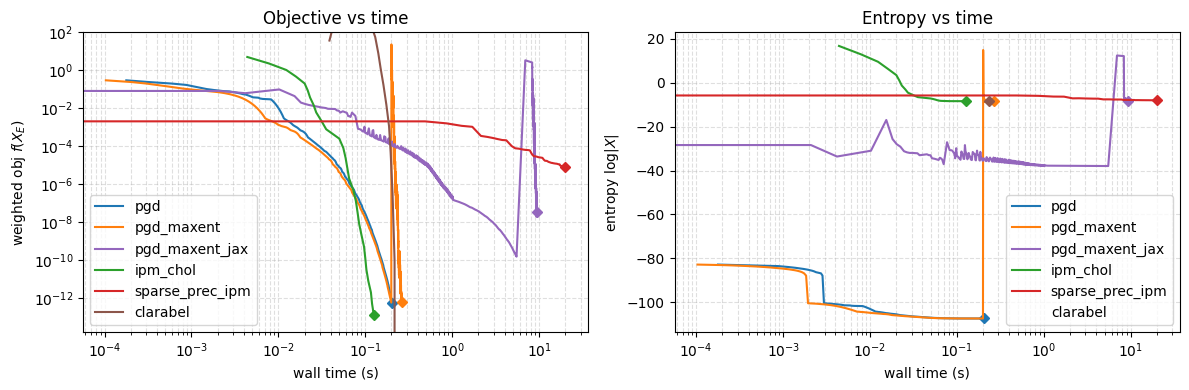

In [125]:
COLORS = {
    'pgd':             'C0',
    'pgd_maxent':      'C1',
    'pgd_maxent_jax':  'C4',
    'ipm_chol':        'C2',
    'sparse_prec_ipm': 'C3',
    'clarabel':        'C5',
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, S, h in results:
    t   = [e['time'] for e in h]
    obj = [e['obj']  for e in h]
    c   = COLORS[name]
    axes[0].loglog(t, obj, label=name, color=c)
    axes[0].loglog([t[-1]], [obj[-1]], color=c, marker='D', markersize=5, linestyle='none')

    # entropy: filter nans (clarabel only has the final value)
    ent_pairs = [(e['time'], e['entropy']) for e in h if not np.isnan(e['entropy'])]
    if ent_pairs:
        te, ent = zip(*ent_pairs)
        axes[1].semilogx(te, ent, label=name, color=c,
                         linestyle='none' if len(ent_pairs) == 1 else '-')
        axes[1].semilogx([te[-1]], [ent[-1]], color=c, marker='D', markersize=5, linestyle='none')

axes[0].set_xlabel('wall time (s)')
axes[0].set_ylabel(r'weighted obj $f(X_E)$')
axes[0].set_title('Objective vs time')
axes[0].legend()
axes[0].grid(True, which='both', linestyle='--', alpha=0.4)
axes[0].set_ylim(top=1e2)

axes[1].set_xlabel('wall time (s)')
axes[1].set_ylabel(r'entropy $\log|X|$')
axes[1].set_title('Entropy vs time')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## Matrix error visualisation

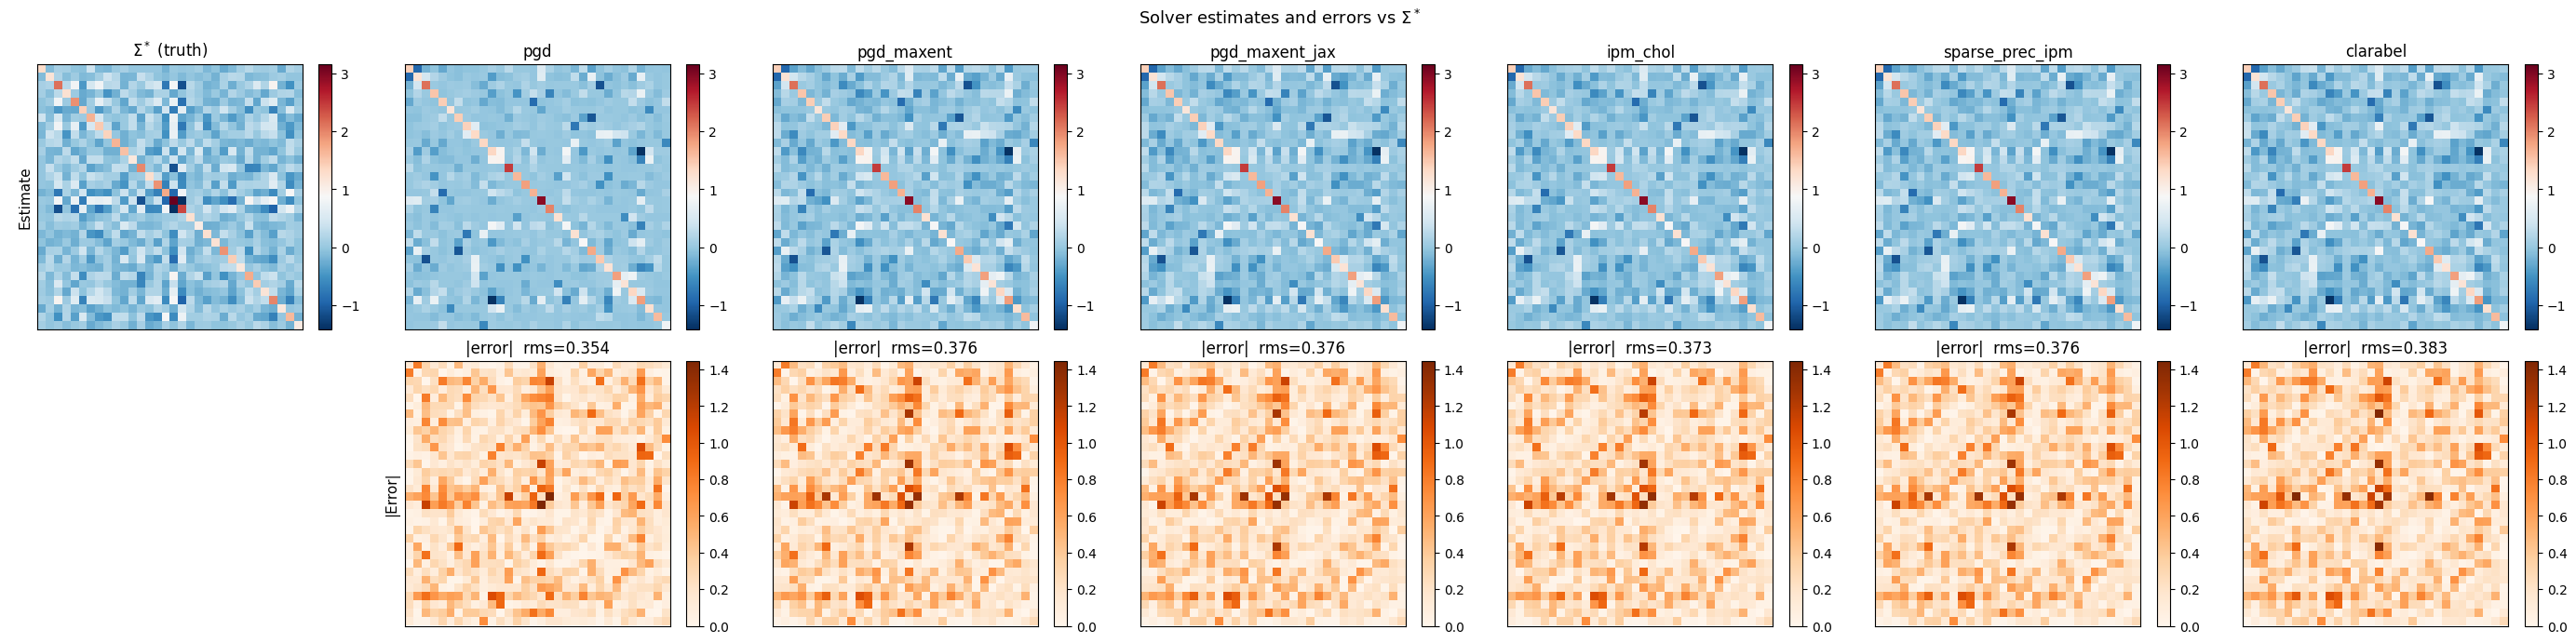

In [126]:
vmin = Sigma_true.min()
vmax = Sigma_true.max()
emax = max(np.abs(Sigma_true - S).max() for _, S, _ in results)
ncols = len(results) + 1

fig, axes = plt.subplots(2, ncols, figsize=(4 * ncols, 7))

# Column 0: truth
im = axes[0, 0].imshow(Sigma_true, vmin=vmin, vmax=vmax, cmap='RdBu_r')
axes[0, 0].set_title(r'$\Sigma^*$ (truth)')
plt.colorbar(im, ax=axes[0, 0], fraction=0.046)
axes[1, 0].axis('off')

# Solver columns
for col, (name, S, h) in enumerate(results, start=1):
    im1 = axes[0, col].imshow(S, vmin=vmin, vmax=vmax, cmap='RdBu_r')
    axes[0, col].set_title(name)
    plt.colorbar(im1, ax=axes[0, col], fraction=0.046)

    err = np.abs(Sigma_true - S)
    im2 = axes[1, col].imshow(err, vmin=0, vmax=emax, cmap='Oranges')
    axes[1, col].set_title(f'|error|  rms={np.sqrt(np.mean(err**2)):.3f}')
    plt.colorbar(im2, ax=axes[1, col], fraction=0.046)

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])

axes[0, 0].set_ylabel('Estimate', fontsize=11)
axes[1, 1].set_ylabel('|Error|', fontsize=11)

plt.suptitle(r'Solver estimates and errors vs $\Sigma^*$', fontsize=13)
plt.tight_layout()
plt.show()

In [119]:
h_sp

[{'time': 5.658299292001175,
  'obj': 22.55519377502612,
  'entropy': -834.7385028148753,
  'mu': 1.0,
  'inner_iters': 200,
  'grad_norm': 60.48304488923067},
 {'time': 5.891464000000269,
  'obj': 22.47792355790148,
  'entropy': -834.7743988103175,
  'mu': 0.3,
  'inner_iters': 200,
  'grad_norm': 1.0481966527370554},
 {'time': 6.1684189590014284,
  'obj': 22.476120083651328,
  'entropy': -834.7656652960859,
  'mu': 0.09,
  'inner_iters': 200,
  'grad_norm': 0.8205237728175443},
 {'time': 6.452316125010839,
  'obj': 22.47594741397137,
  'entropy': -834.7633962480005,
  'mu': 0.027,
  'inner_iters': 200,
  'grad_norm': 0.4343849135153276},
 {'time': 6.8120153339987155,
  'obj': 22.47594741397137,
  'entropy': -834.7633962480005,
  'mu': 0.0081,
  'inner_iters': 200,
  'grad_norm': 0.282278758401679},
 {'time': 7.158651917008683,
  'obj': 22.47594741397137,
  'entropy': -834.7633962480005,
  'mu': 0.00243,
  'inner_iters': 200,
  'grad_norm': 0.29942598710450197},
 {'time': 7.5276420840